# Hard Hat Detection with YOLO11s

**Zaid Rasras**

Object detection on the [Hard Hat Detection dataset](https://www.kaggle.com/datasets/andrewmvd/hard-hat-detection). This notebook includes an initial three-class experiment followed by a final two-class helmet/head model.


## 1. Import Libraries and Convert Annotations

Import the required libraries, read the Pascal VOC XML files, and convert bounding boxes to normalized YOLO coordinates. Store one row per annotated object in a DataFrame. The initial experiment uses helmet, head, and person classes.


In [26]:
import os
import glob
import xml.etree.ElementTree as ET
import pandas as pd


# 1. Automatically find the annotations folder inside /kaggle/input
annot_dirs = glob.glob('/kaggle/input/**/annotations', recursive=True)
if not annot_dirs:
    raise FileNotFoundError("Could not find 'annotations' folder inside /kaggle/input")

annot_dir = annot_dirs[0]
xml_files = sorted(glob.glob(os.path.join(annot_dir, '*.xml')))
print(f"Found {len(xml_files)} XML files in: {annot_dir}")

class_map = {'helmet': 0, 'head': 1, 'person': 2}
records = []

for xml_file in xml_files:
    tree = ET.parse(xml_file)
    root = tree.getroot()
    
    filename = root.find('filename').text
    size = root.find('size')
    img_w = float(size.find('width').text)
    img_h = float(size.find('height').text)
    
    for obj in root.findall('object'):
        cls_name = obj.find('name').text
        if cls_name not in class_map:
            continue

        bndbox = obj.find('bndbox')
        xmin = float(bndbox.find('xmin').text)
        ymin = float(bndbox.find('ymin').text)
        xmax = float(bndbox.find('xmax').text)
        ymax = float(bndbox.find('ymax').text)
        
        x_center = ((xmin + xmax) / 2.0) / img_w
        y_center = ((ymin + ymax) / 2.0) / img_h
        w_norm = (xmax - xmin) / img_w
        h_norm = (ymax - ymin) / img_h
        
        records.append({
            'filename': filename,
            'class': cls_name,
            'class_id': class_map[cls_name],
            'img_w': img_w,
            'img_h': img_h,
            'xmin': xmin,
            'ymin': ymin,
            'xmax': xmax,
            'ymax': ymax,
            'x_center': x_center,
            'y_center': y_center,
            'w_norm': w_norm,
            'h_norm': h_norm
        })

df = pd.DataFrame(records)

if not df.empty:
    for col in ['x_center', 'y_center', 'w_norm', 'h_norm']:
        df[col] = df[col].clip(0.0, 1.0)

print(f"Total rows (objects): {len(df)}")
df.head()

Found 5000 XML files in: /kaggle/input/datasets/andrewmvd/hard-hat-detection/annotations
Total rows (objects): 25502


,filename,class,class_id,img_w,img_h,xmin,ymin,xmax,ymax,x_center,y_center,w_norm,h_norm
0,hard_hat_workers0.png,helmet,0,416.0,416.0,357.0,116.0,404.0,175.0,0.914663,0.349760,0.112981,0.141827
1,hard_hat_workers0.png,helmet,0,416.0,416.0,4.0,146.0,39.0,184.0,0.051683,0.396635,0.084135,0.091346
2,hard_hat_workers0.png,helmet,0,416.0,416.0,253.0,139.0,275.0,177.0,0.634615,0.379808,0.052885,0.091346
3,hard_hat_workers0.png,helmet,0,416.0,416.0,300.0,145.0,323.0,181.0,0.748798,0.391827,0.055288,0.086538
4,hard_hat_workers0.png,helmet,0,416.0,416.0,116.0,151.0,138.0,180.0,0.305288,0.397837,0.052885,0.069712


## 2. Prepare the Initial Dataset

Split the images into 80% training and 20% validation data. Copy images, write matching YOLO label files, and create data.yaml with the class names and dataset paths.


In [28]:
import os
import shutil
import yaml
from sklearn.model_selection import train_test_split

# 1. Define input and output paths
img_dir = '/kaggle/input/datasets/andrewmvd/hard-hat-detection/images'
base_dir = '/kaggle/working/yolo_dataset'

# 2. Split by unique image filenames (80% train, 20% val)
unique_images = df['filename'].unique()
train_imgs, val_imgs = train_test_split(unique_images, test_size=0.2, random_state=42)

def export_split(image_list, split_name):
    img_out_dir = os.path.join(base_dir, 'images', split_name)
    lbl_out_dir = os.path.join(base_dir, 'labels', split_name)
    os.makedirs(img_out_dir, exist_ok=True)
    os.makedirs(lbl_out_dir, exist_ok=True)

    grouped = df[df['filename'].isin(image_list)].groupby('filename')

    for img_name in image_list:
        shutil.copy(os.path.join(img_dir, img_name), os.path.join(img_out_dir, img_name))

        txt_name = os.path.splitext(img_name)[0] + '.txt'
        txt_path = os.path.join(lbl_out_dir, txt_name)

        if img_name in grouped.groups:
            rows = grouped.get_group(img_name)
            with open(txt_path, 'w') as f:
                for _, row in rows.iterrows():
                    f.write(
                        f"{int(row['class_id'])} "
                        f"{row['x_center']:.6f} "
                        f"{row['y_center']:.6f} "
                        f"{row['w_norm']:.6f} "
                        f"{row['h_norm']:.6f}\n"
                    )
        else:
            open(txt_path, 'w').close()

export_split(train_imgs, 'train')
export_split(val_imgs, 'val')

# 3. Create data.yaml
data_yaml = {
    'path': base_dir,
    'train': 'images/train',
    'val': 'images/val',
    'nc': 3,
    'names': {0: 'helmet', 1: 'head', 2: 'person'}
}

yaml_path = os.path.join(base_dir, 'data.yaml')
with open(yaml_path, 'w') as f:
    yaml.dump(data_yaml, f, sort_keys=False)

print(f"Exported! Train: {len(train_imgs)} | Val: {len(val_imgs)}")

# 4. Sanity check: inspect one generated label file
sample_txt = os.listdir('/kaggle/working/yolo_dataset/labels/train')[0]
with open(f'/kaggle/working/yolo_dataset/labels/train/{sample_txt}') as f:
    print(f"\nSample file ({sample_txt}):\n" + f.read())

Exported! Train: 4000 | Val: 1000

Sample file (hard_hat_workers4563.txt):
0 0.796875 0.462740 0.165865 0.204327



## 3. Train the Initial YOLO11s Model

Load pretrained YOLO11s weights and train the three-class detector for 30 epochs with image size 640 and batch size 16.


In [31]:
!pip install -q ultralytics

from ultralytics import YOLO

# 1. Load a pretrained YOLO model
model = YOLO('yolo11s.pt')

# 2. Train on your custom dataset
results = model.train(
    data='/kaggle/working/yolo_dataset/data.yaml',
    epochs=30,
    imgsz=640,
    batch=16,
    device=0,
    project='/kaggle/working/runs',
    name='hardhat_yolo11s',
    patience=10,
    workers=2
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/yolo_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fract

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/30      5.12G      1.463      1.025      1.288        132        640: 100% ━━━━━━━━━━━━ 250/250 5.0it/s 49.6s0.2ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 32/32 3.9it/s 8.3s0.3s
                   all       1000       5146      0.887      0.523      0.563      0.333

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/30      5.12G      1.439      1.013      1.275        107        640: 100% ━━━━━━━━━━━━ 250/250 4.5it/s 55.0s0.2ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 32/32 3.9it/s 8.1s0.3s
                   all       1000       5146      0.881      0.512      0.559      0.334

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/30      5.12G      1.428     0.9754      1.268        141        640: 100% ━━━━━━━━━━━━ 250/250 4.6it/s 54.3s0.2ss
                 Class     Ima

## 4. Validate and Visualize Predictions

Evaluate the best checkpoint on validation data. Display training curves, the confusion matrix, and predictions on sample validation images. The initial results show much weaker person detection than helmet and head detection.


Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s summary (fused): 100 layers, 9,413,961 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3818.8±955.3 MB/s, size: 250.7 KB)
val: Scanning /kaggle/working/yolo_dataset/labels/val.cache... 1000 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1000/1000 322.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 63/63 3.7it/s 16.9s0.3s
                   all       1000       5146      0.946      0.597      0.637      0.421
                helmet        902       3659      0.952      0.914      0.971      0.648
                  head        192       1276      0.887      0.877      0.921      0.609
                person         40        211          1          0     0.0187    0.00726
Speed: 0.9ms preprocess, 12.2ms inference, 0.0ms loss, 0.9ms postprocess per image
Results saved to /kaggle/worki

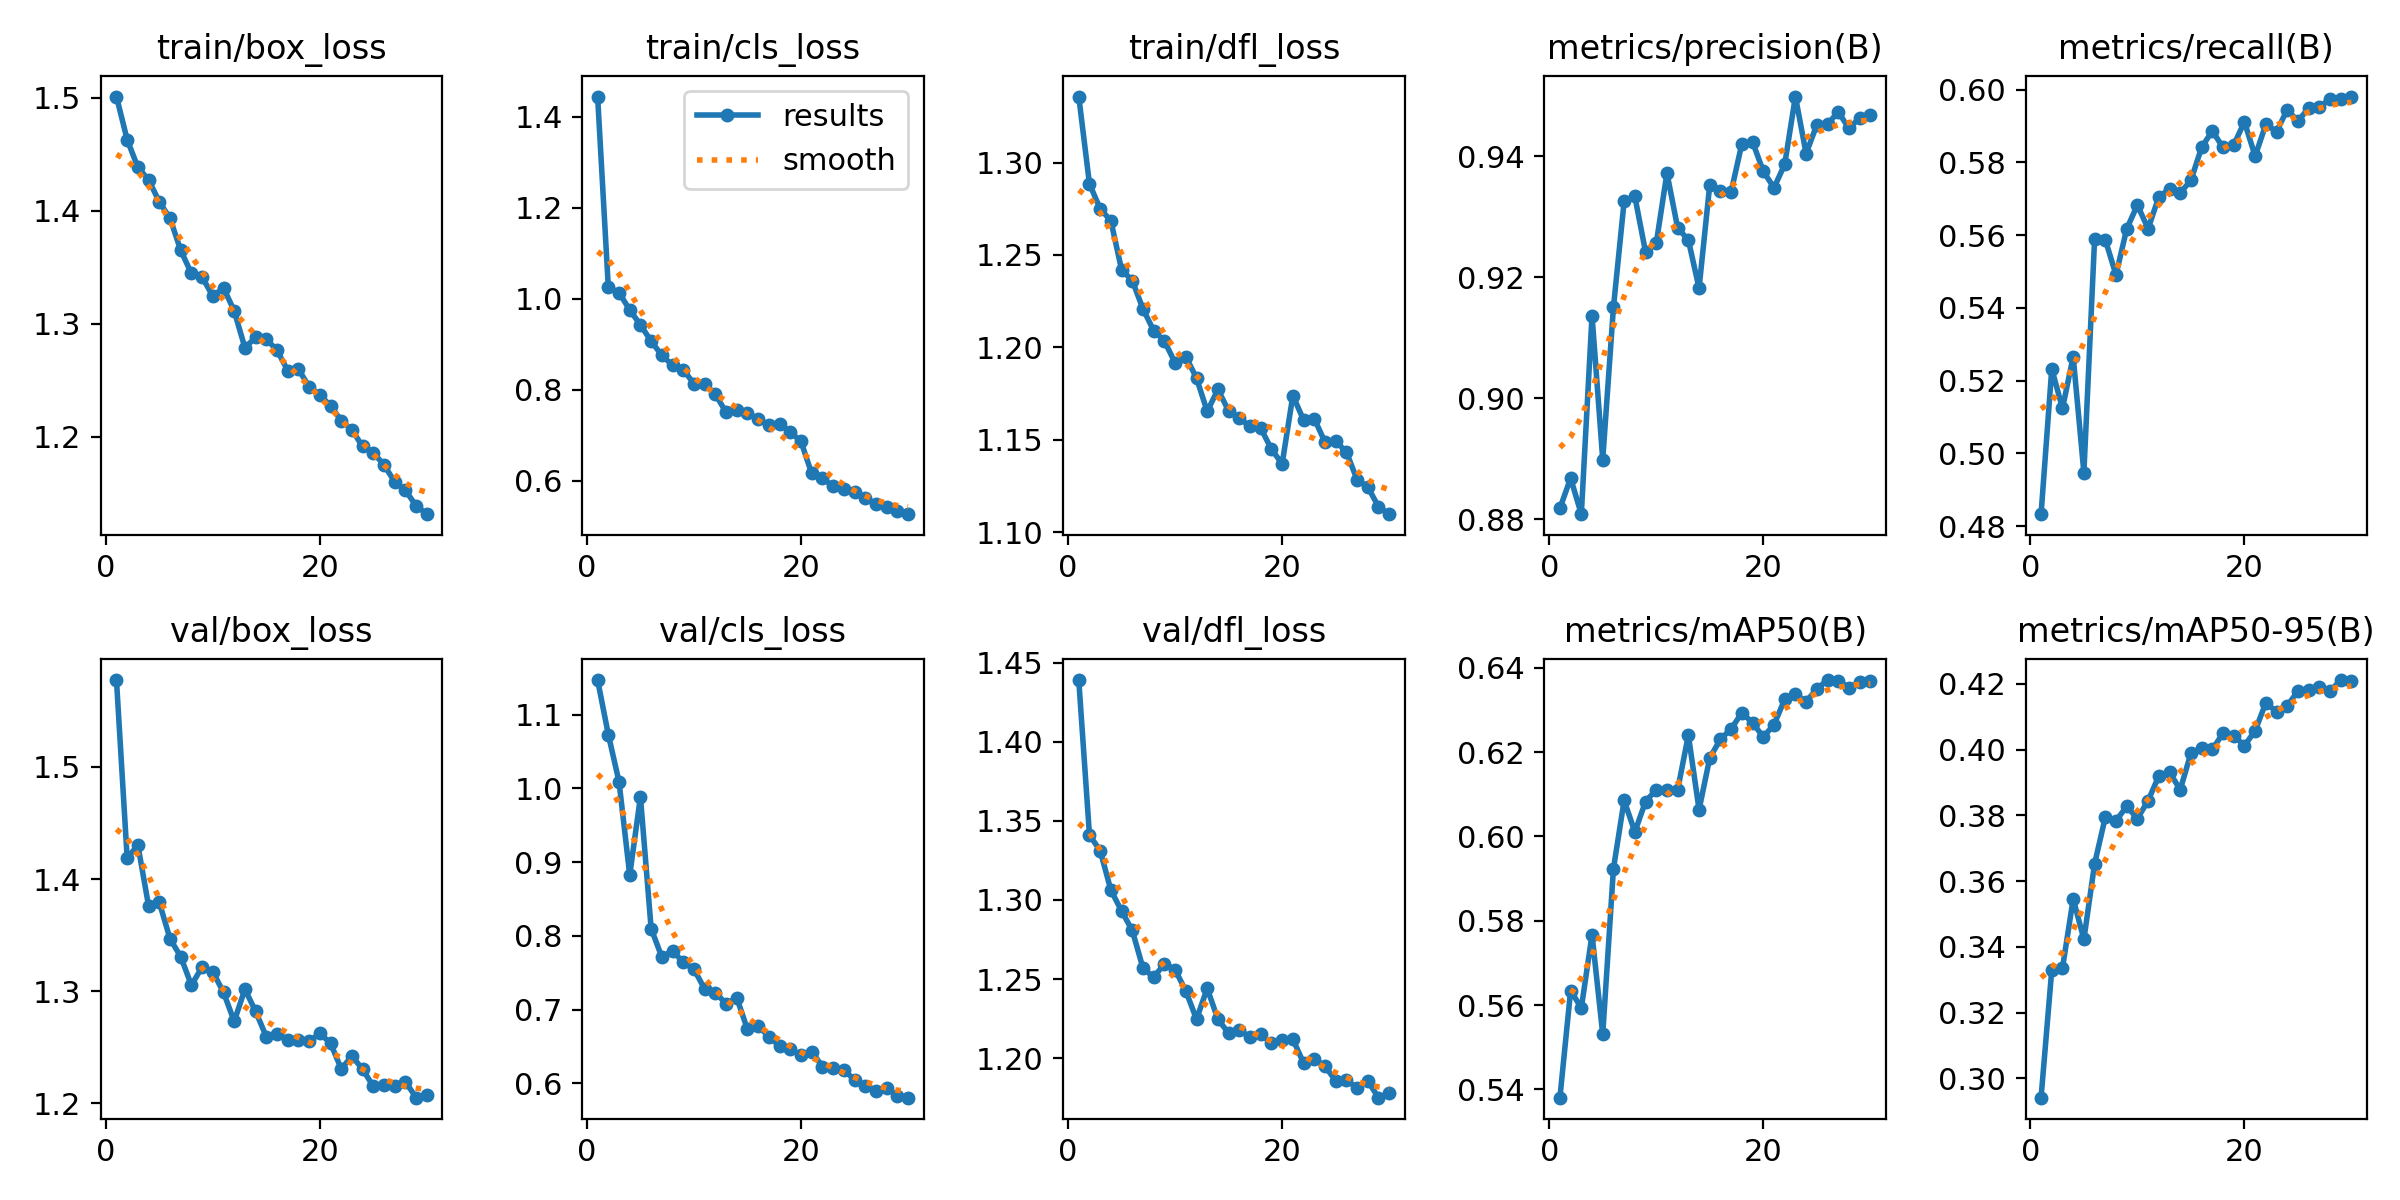


--- confusion_matrix_normalized.png ---


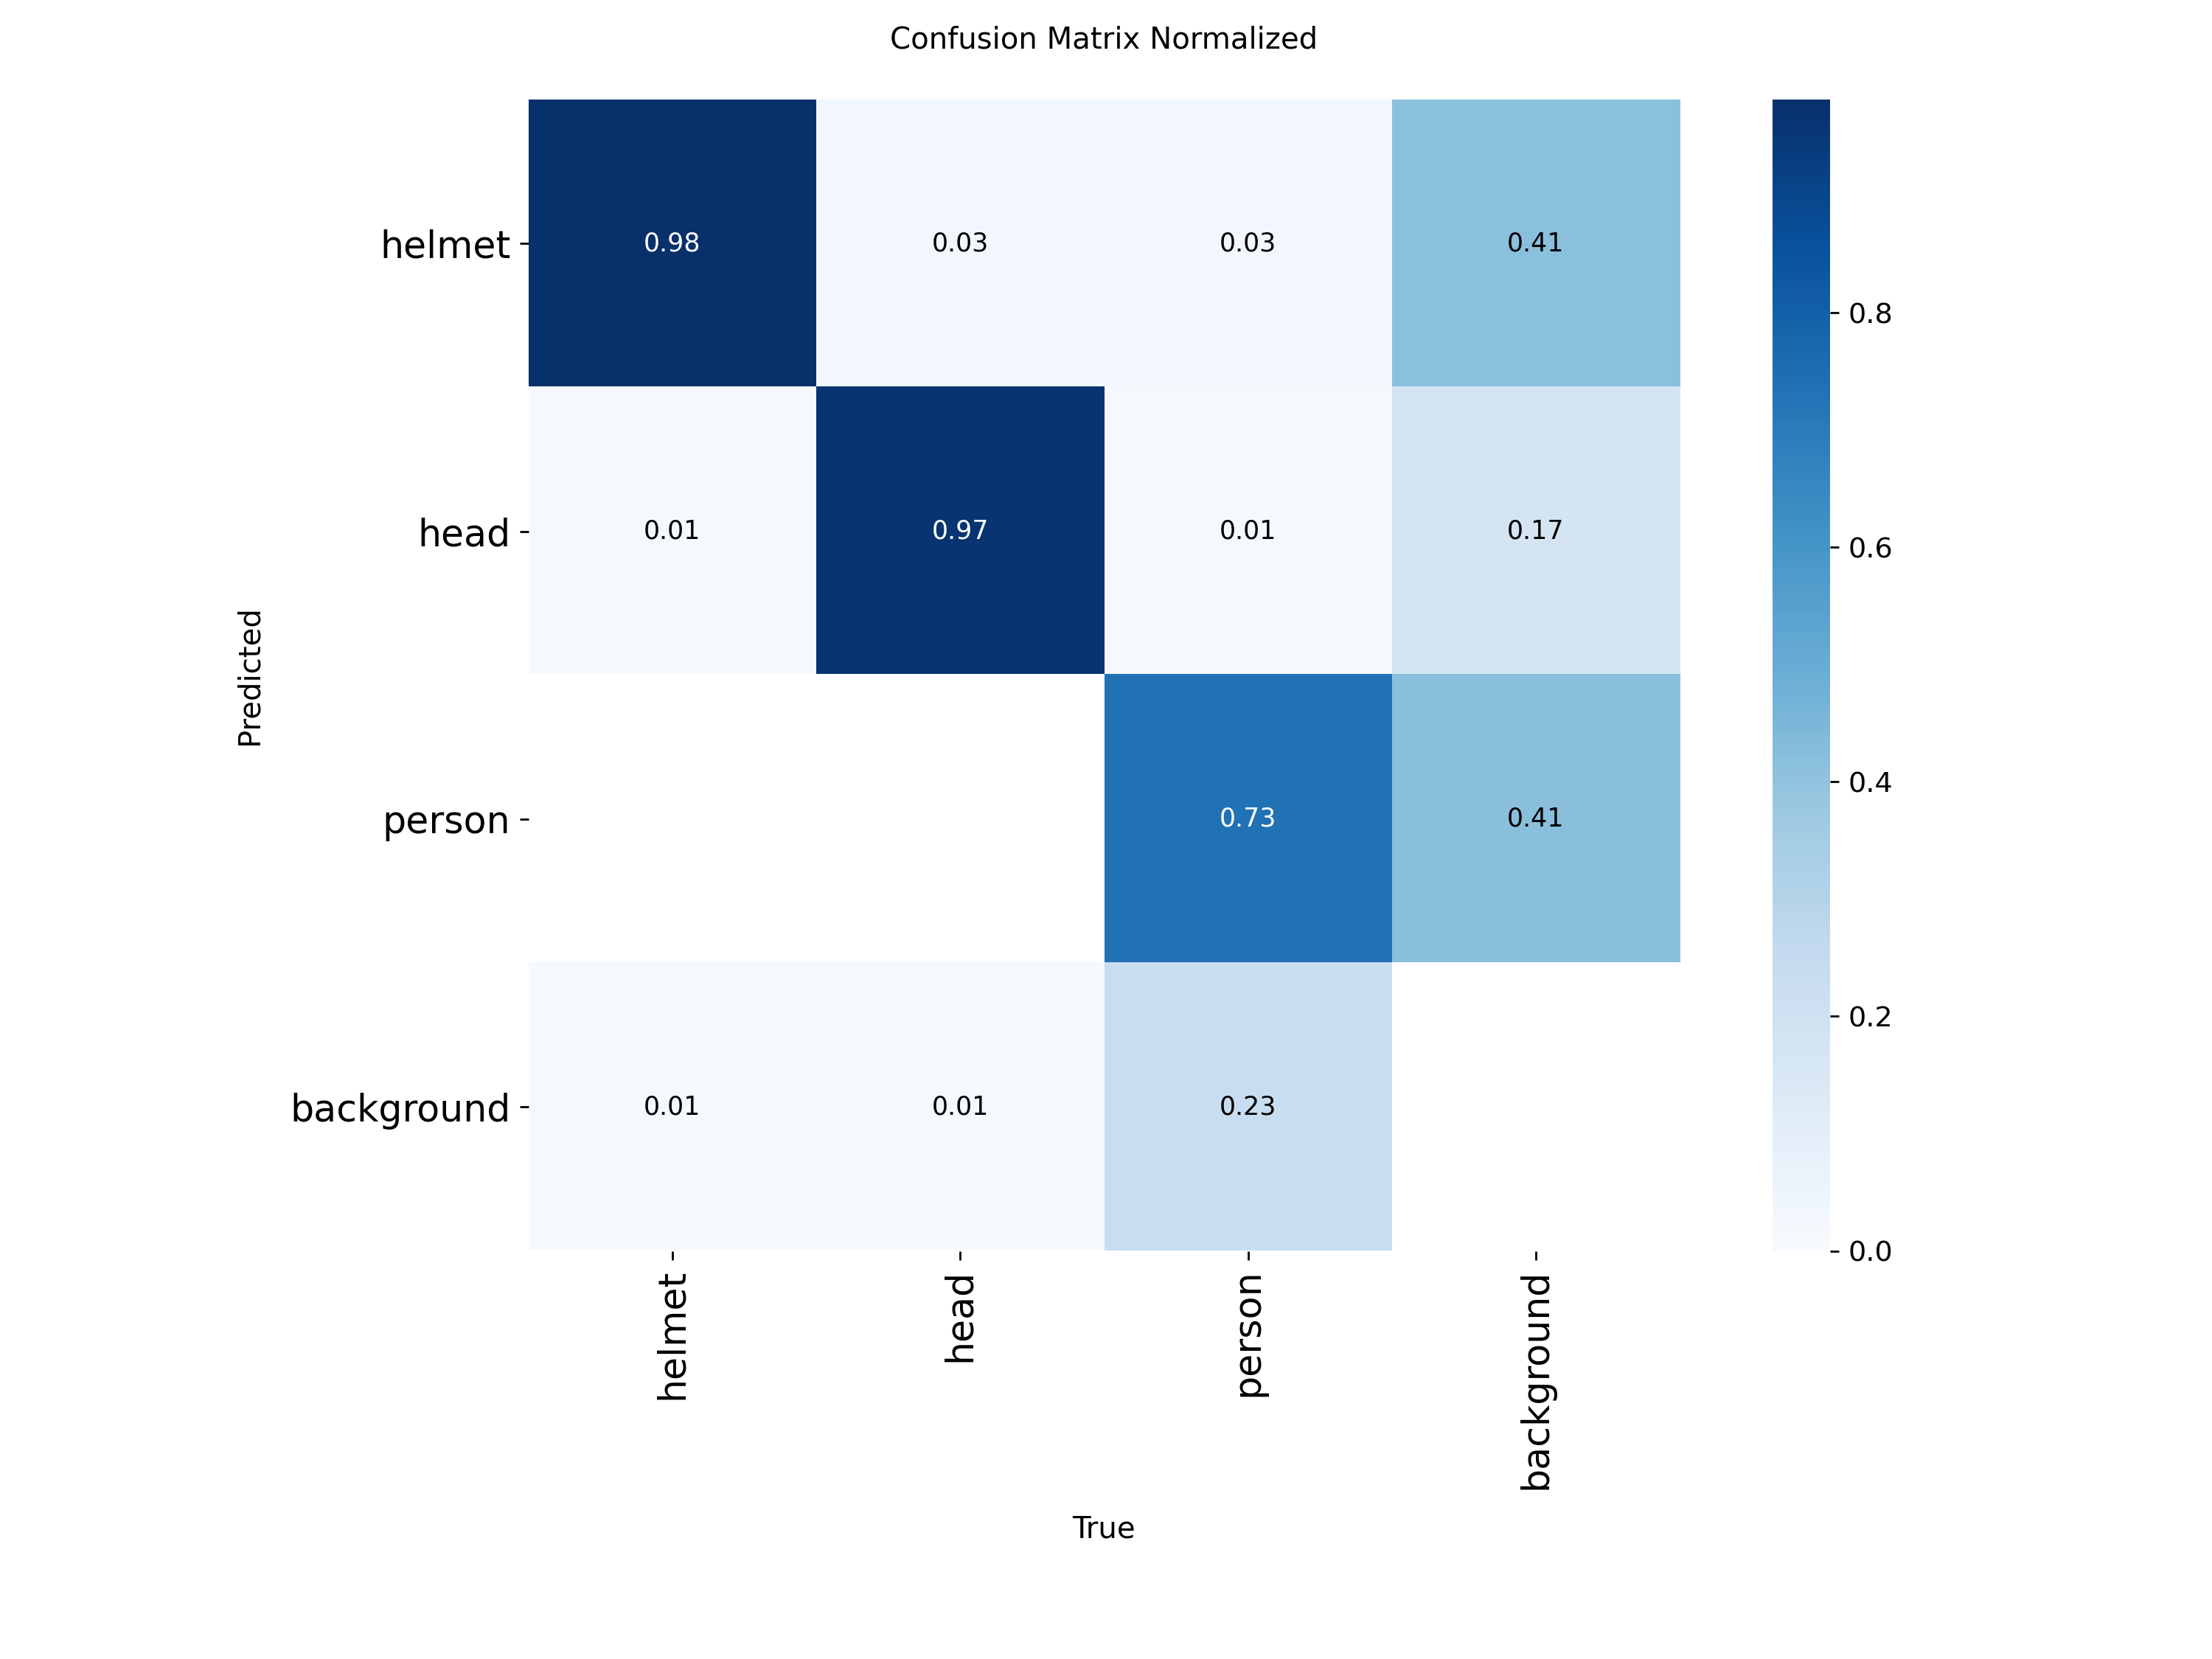

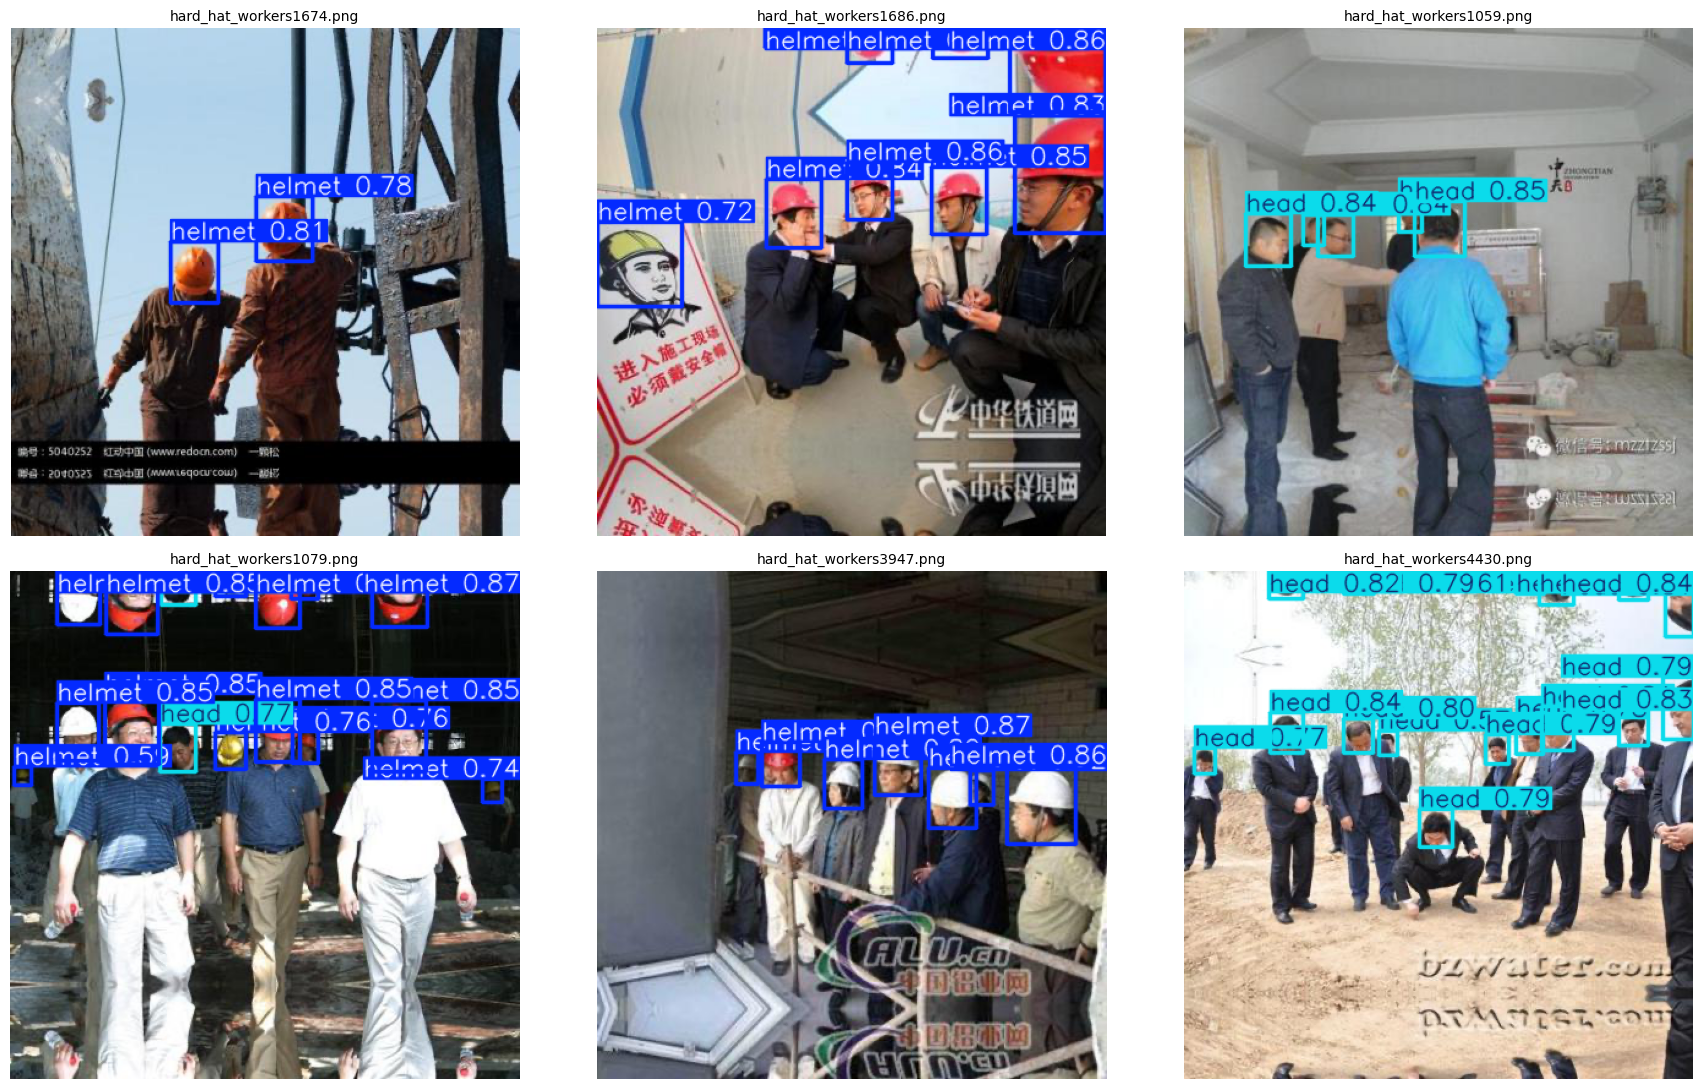

In [32]:
import glob
import random
import cv2
import matplotlib.pyplot as plt
from IPython.display import Image, display
from ultralytics import YOLO

# 1. Load the best checkpoint saved during training
best_model = YOLO('/kaggle/working/runs/hardhat_yolo11s/weights/best.pt')

# 2. Run formal validation to get per-class Precision, Recall, and mAP
metrics = best_model.val(data='/kaggle/working/yolo_dataset/data.yaml')
print(f"mAP50: {metrics.box.map50:.4f} | mAP50-95: {metrics.box.map:.4f}")

# 3. Display YOLO's built-in training curves & confusion matrix
for plot_name in ['results.png', 'confusion_matrix_normalized.png']:
    plot_path = f'/kaggle/working/runs/hardhat_yolo11s/{plot_name}'
    print(f"\n--- {plot_name} ---")
    display(Image(filename=plot_path, width=800))

# 4. Run inference on 6 random validation images and plot them
val_images = glob.glob('/kaggle/working/yolo_dataset/images/val/*')
sample_imgs = random.sample(val_images, 6)

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
for ax, img_path in zip(axes.flatten(), sample_imgs):
    # Predict with confidence threshold 0.4
    preds = best_model.predict(img_path, conf=0.4, verbose=False)[0]
    annotated_bgr = preds.plot()  # Returns BGR image with boxes & labels drawn
    annotated_rgb = cv2.cvtColor(annotated_bgr, cv2.COLOR_BGR2RGB)
    
    ax.imshow(annotated_rgb)
    ax.set_title(img_path.split('/')[-1], fontsize=10)
    ax.axis('off')

plt.tight_layout()
plt.show()

## 5. Export the Initial Model

Export the initial trained model to ONNX format for use with compatible inference runtimes.


In [33]:
best_model.export(format='onnx', imgsz=640)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO11s summary (fused): 100 layers, 9,413,961 parameters, 0 gradients, 21.4 GFLOPs

PyTorch: starting from '/kaggle/working/runs/hardhat_yolo11s/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 7, 8400) (18.3 MB)
requirements: Ultralytics requirements ['onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 12 packages in 423ms
Prepared 2 packages in 4.77s
Installed 2 packages in 11ms
 + onnxruntime==1.32.0
 + onnxslim==0.1.99

requirements: AutoUpdate success ✅ 5.7s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: slimming with onnxslim 0.1.99...
ONNX: export success ✅ 8.

'/kaggle/working/runs/hardhat_yolo11s/weights/best.onnx'

## 6. Display Helmet and Head Counts

Predict objects in a sample image and display helmet and head detection counts. The alert overlay is a demonstration; detected boxes do not establish the safety status of every worker.


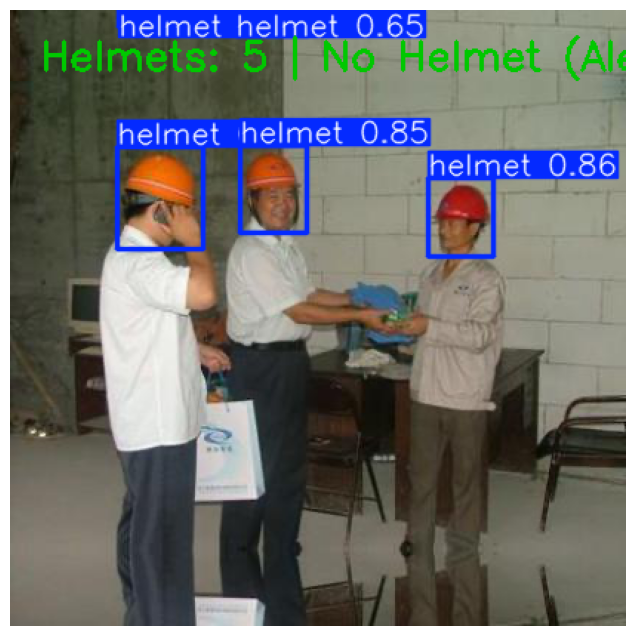

In [35]:
import glob
import random
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

# 1. Use the full path to your trained weights in Kaggle
model = YOLO('/kaggle/working/runs/hardhat_yolo11s/weights/best.pt')

# 2. Pick a random validation image to test the safety counter overlay
sample_img_path = random.choice(glob.glob('/kaggle/working/yolo_dataset/images/val/*'))
frame = cv2.imread(sample_img_path)

# 3. Run inference and draw boxes
results = model.predict(frame, conf=0.45, imgsz=640, verbose=False)[0]
annotated_frame = results.plot()

# 4. Count compliant (helmet = 0) vs. non-compliant (head = 1)
classes = results.boxes.cls.tolist()
helmets = classes.count(0)
heads = classes.count(1)

status_color = (0, 0, 255) if heads > 0 else (0, 200, 0)
status_text = f"Helmets: {helmets} | No Helmet (Alert): {heads}"
cv2.putText(annotated_frame, status_text, (20, 40),
            cv2.FONT_HERSHEY_SIMPLEX, 0.9, status_color, 2)

# 5. Display using Matplotlib (since cv2.imshow doesn't work in Kaggle notebooks)
plt.figure(figsize=(10, 8))
plt.imshow(cv2.cvtColor(annotated_frame, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

## 7. Prepare the Final Two-Class Dataset

Keep helmet (0) and head (1), skip zero-area boxes, and export a new dataset. Group images with identical 8×8 average hashes before splitting to reduce some duplicate leakage. This is a limited similarity check, not a guarantee that all related images stay together. The saved split contains 3,509 training, 746 validation, and 745 test images. Rerunning this cell recreates the yolo_dataset_v2 output folder.


In [36]:
import os
import glob
import shutil
import yaml
import cv2
import numpy as np
import xml.etree.ElementTree as ET
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

# 1. Parse XMLs for the 2-class task (0: helmet, 1: head)
annot_dir = '/kaggle/input/datasets/andrewmvd/hard-hat-detection/annotations'
img_dir = '/kaggle/input/datasets/andrewmvd/hard-hat-detection/images'
base_dir = '/kaggle/working/yolo_dataset_v2'

if os.path.exists(base_dir):
    shutil.rmtree(base_dir)

class_map = {'helmet': 0, 'head': 1}
records = []

for xml_file in sorted(glob.glob(os.path.join(annot_dir, '*.xml'))):
    tree = ET.parse(xml_file)
    root = tree.getroot()
    filename = root.find('filename').text
    size = root.find('size')
    img_w = float(size.find('width').text)
    img_h = float(size.find('height').text)

    for obj in root.findall('object'):
        cls_name = obj.find('name').text
        if cls_name not in class_map:
            continue

        bndbox = obj.find('bndbox')
        xmin, ymin = float(bndbox.find('xmin').text), float(bndbox.find('ymin').text)
        xmax, ymax = float(bndbox.find('xmax').text), float(bndbox.find('ymax').text)

        # Skip degenerate zero-area boxes
        if xmax <= xmin or ymax <= ymin:
            continue

        x_center = np.clip(((xmin + xmax) / 2.0) / img_w, 0.0, 1.0)
        y_center = np.clip(((ymin + ymax) / 2.0) / img_h, 0.0, 1.0)
        w_norm = np.clip((xmax - xmin) / img_w, 0.0, 1.0)
        h_norm = np.clip((ymax - ymin) / img_h, 0.0, 1.0)

        records.append({
            'filename': filename,
            'class_id': class_map[cls_name],
            'x_center': x_center,
            'y_center': y_center,
            'w_norm': w_norm,
            'h_norm': h_norm
        })

df_v2 = pd.DataFrame(records)

# 2. Compute simple average hash (dHash/aHash) per image to group near-duplicates
all_images = sorted(os.listdir(img_dir))
img_hashes = {}
for img_name in all_images:
    img = cv2.imread(os.path.join(img_dir, img_name), cv2.IMREAD_GRAYSCALE)
    if img is None:
        continue
    small = cv2.resize(img, (8, 8), interpolation=cv2.INTER_AREA)
    bits = (small > small.mean()).flatten()
    img_hashes[img_name] = ''.join(['1' if b else '0' for b in bits])

img_df = pd.DataFrame({'filename': list(img_hashes.keys()), 'hash': list(img_hashes.values())})
print(f"Total valid images: {len(img_df)} | Unique perceptual hashes: {img_df['hash'].nunique()}")

# 3. Group-aware split: 70% Train, 15% Val, 15% Test (duplicates stay in the same split)
gss_test = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=42)
train_val_idx, test_idx = next(gss_test.split(img_df, groups=img_df['hash']))
train_val_df = img_df.iloc[train_val_idx].reset_index(drop=True)
test_imgs = img_df.iloc[test_idx]['filename'].tolist()

# 0.15 / 0.85 ≈ 0.1765 of remaining data gives 15% of total dataset for val
gss_val = GroupShuffleSplit(n_splits=1, test_size=0.1765, random_state=42)
train_idx, val_idx = next(gss_val.split(train_val_df, groups=train_val_df['hash']))
train_imgs = train_val_df.iloc[train_idx]['filename'].tolist()
val_imgs = train_val_df.iloc[val_idx]['filename'].tolist()

# 4. Export images & YOLO .txt labels
def export_split(image_list, split_name):
    img_out = os.path.join(base_dir, 'images', split_name)
    lbl_out = os.path.join(base_dir, 'labels', split_name)
    os.makedirs(img_out, exist_ok=True)
    os.makedirs(lbl_out, exist_ok=True)

    grouped = df_v2[df_v2['filename'].isin(image_list)].groupby('filename')
    for img_name in image_list:
        shutil.copy(os.path.join(img_dir, img_name), os.path.join(img_out, img_name))
        txt_path = os.path.join(lbl_out, os.path.splitext(img_name)[0] + '.txt')
        if img_name in grouped.groups:
            rows = grouped.get_group(img_name)
            with open(txt_path, 'w') as f:
                for _, r in rows.iterrows():
                    f.write(f"{int(r['class_id'])} {r['x_center']:.6f} {r['y_center']:.6f} {r['w_norm']:.6f} {r['h_norm']:.6f}\n")
        else:
            open(txt_path, 'w').close()

export_split(train_imgs, 'train')
export_split(val_imgs, 'val')
export_split(test_imgs, 'test')

# 5. Write data.yaml with explicit test split
data_yaml = {
    'path': base_dir,
    'train': 'images/train',
    'val': 'images/val',
    'test': 'images/test',
    'nc': 2,
    'names': {0: 'helmet', 1: 'head'}
}
with open(os.path.join(base_dir, 'data.yaml'), 'w') as f:
    yaml.dump(data_yaml, f, sort_keys=False)

print(f"Split complete -> Train: {len(train_imgs)} | Val: {len(val_imgs)} | Test: {len(test_imgs)}")

Total valid images: 5000 | Unique perceptual hashes: 4852
Split complete -> Train: 3509 | Val: 746 | Test: 745


## 8. Train the Final Two-Class Model

Start from fresh pretrained YOLO11s weights and train the helmet/head detector for 30 epochs. Validation data is used during training; the test split is reserved for the final evaluation.


In [37]:
from ultralytics import YOLO

# 1. Load fresh pretrained weights (never resume from the 3-class checkpoint)
model_v2 = YOLO('yolo11s.pt')

# 2. Train on the clean 2-class dataset (70% train / 15% val; test stays locked)
results_v2 = model_v2.train(
    data='/kaggle/working/yolo_dataset_v2/data.yaml',
    epochs=30,
    imgsz=640,
    batch=16,
    device=0,
    project='/kaggle/working/runs',
    name='hardhat_yolo11s_2class',
    patience=10,
    workers=2
)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/yolo_dataset_v2/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=hardhat_yolo11s_2class, nbs=64, nms=None, opse

## 9. Final Evaluation and ONNX Comparison

Select a confidence threshold using the validation F1 curve, then evaluate on the test split. Test AP is calculated after filtering predictions at that selected threshold. Export the final model to ONNX, compare detection counts and confidence scores on one test image, and save package versions. This single-image comparison is a basic check rather than comprehensive equivalence testing.


In [38]:
import glob
import random
import numpy as np
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

# 1. Load your newly trained 2-class checkpoint
best_pt_path = '/kaggle/working/runs/hardhat_yolo11s_2class/weights/best.pt'
model = YOLO(best_pt_path)
data_yaml_path = '/kaggle/working/yolo_dataset_v2/data.yaml'

# 2. Select the optimal confidence threshold using VALIDATION data only
val_metrics = model.val(data=data_yaml_path, split='val', verbose=False)
# val_metrics.box.f1_curve has shape (num_classes, 1000) across conf thresholds [0.001 .. 1.0]
mean_f1_curve = val_metrics.box.f1_curve.mean(axis=0)
best_idx = int(np.argmax(mean_f1_curve))
best_conf = float(val_metrics.box.px[best_idx])
print(f"Optimal Validation Confidence Threshold: {best_conf:.3f} (Mean Val F1: {mean_f1_curve[best_idx]:.4f})")

# 3. Evaluate ONCE on the untouched TEST set using the validation-selected threshold
test_metrics = model.val(data=data_yaml_path, split='test', conf=best_conf, verbose=True)
print(f"\n=== FINAL TEST SET RESULTS (conf={best_conf:.3f}) ===")
print(f"Test mAP50:    {test_metrics.box.map50:.4f}")
print(f"Test mAP50-95: {test_metrics.box.map:.4f}")
for i, cls_name in model.names.items():
    p, r, ap50, ap = test_metrics.box.class_result(i)
    print(f"Class '{cls_name}' -> Precision: {p:.4f} | Recall: {r:.4f} | mAP50: {ap50:.4f}")

# 4. Export to ONNX & verify prediction parity against PyTorch on a test image
onnx_path = model.export(format='onnx', imgsz=640)
onnx_model = YOLO(onnx_path)

sample_test_img = random.choice(glob.glob('/kaggle/working/yolo_dataset_v2/images/test/*'))
pt_res = model.predict(sample_test_img, conf=best_conf, imgsz=640, verbose=False)[0]
onnx_res = onnx_model.predict(sample_test_img, conf=best_conf, imgsz=640, verbose=False)[0]

print(f"\n=== ONNX PARITY CHECK ({sample_test_img.split('/')[-1]}) ===")
print(f"PyTorch boxes: {len(pt_res.boxes)} | Scores: {np.round(pt_res.boxes.conf.cpu().numpy(), 4)}")
print(f"ONNX boxes:    {len(onnx_res.boxes)} | Scores: {np.round(onnx_res.boxes.conf.cpu().numpy(), 4)}")

# 5. Save environment versions for reproducibility
!pip freeze > /kaggle/working/requirements.txt
print("\nSaved environment details to /kaggle/working/requirements.txt")

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s summary (fused): 100 layers, 9,413,574 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3717.8±1087.5 MB/s, size: 284.4 KB)
val: Scanning /kaggle/working/yolo_dataset_v2/labels/val.cache... 746 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 746/746 223.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 47/47 3.6it/s 13.1s0.3s
                   all        746       3490       0.91      0.895      0.935      0.614
Speed: 0.9ms preprocess, 12.5ms inference, 0.0ms loss, 0.9ms postprocess per image
Results saved to /kaggle/working/runs/detect/val-2
Optimal Validation Confidence Threshold: 0.452 (Mean Val F1: 0.9032)
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s summary (fused): 100 layers, 9,413,574 parameters, 0 gradients, 21.4 GFLOPs
val: Fas